# NIH Chest X-ray: Tabular Baseline Model

### Project Objective

Build a baseline machine learning model to predict one (1) selected chest X-ray finding using patient and image metadata from the NIH ChestX-ray14 dataset.

### Project Workflow

1. **Define prediction target** -- Select a chest X-ray finding as prediction target, based on its prevalence and suitability for a baseline model.
2. **Prepare target label** -- Inspect the dataset and target labels. Convert multi-label "Finding Labels" column into a binary target: 1 if selected finding is present and 0 otherwise.
3. **Build metadata feature set** -- Use Age, Gender, View Position, and Follow-up number as initial features.
4. **Address class imbalance and data leakage** -- Inspect the class distribution, use stratified validation with class weighting. Ensure images from the same patient do not appear in both training and validation sets.
5. **Train and evaluate a baseline model** -- Use a scikit-learn pipeline with a baseline classifier, and evaluate it using ROC-AUC, precision-recall, and other appropriate metrics beyond accuracy.
6. **Interpret the model** -- Use SHAP or other feature importance methods to explore how metadata features relate to predictions, with a short write-up on clinical interpretation and discuss limitations.

### Important Note

This model uses metadata rather than actual X-ray images. It explores associations between metadata and dataset labels -- it does not diagnose disease from medical images.

## 01. Load Data

In [7]:
# Import libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Load data
df = pd.read_csv("/Users/hweeenheah/Downloads/EDA_Resources/nih-chestxray-ml/sql-eda/Data_Entry_2017.csv")
print("Dataset shape:", df.shape)
print(df.head())

print("Libraries Imported. Set up Complete.")

Dataset shape: (112120, 12)
        Image Index          Finding Labels  Follow-up #  Patient ID  \
0  00000001_000.png            Cardiomegaly            0           1   
1  00000001_001.png  Cardiomegaly|Emphysema            1           1   
2  00000001_002.png   Cardiomegaly|Effusion            2           1   
3  00000002_000.png              No Finding            0           2   
4  00000003_000.png                  Hernia            0           3   

   Patient Age Patient Gender View Position  OriginalImage[Width  Height]  \
0           58              M            PA                 2682     2749   
1           58              M            PA                 2894     2729   
2           58              M            PA                 2500     2048   
3           81              M            PA                 2500     2048   
4           81              F            PA                 2582     2991   

   OriginalImagePixelSpacing[x     y]  Unnamed: 11  
0                      

## 02. Define prediction target

Effusion is selected as the initial prediction target bevause it is clinically meaningful and allows us to investigate how demongraphic and imaging metadata relate to recorded pleural effusion labels. Effusion also has a reasonably high prevalance in this dataset (13317 out of 112120 positive effusion cases, approx 11-12%), giving us enough positive cases to work with. 

This project will invesetigate predictive associations rather than establish diagnostic accuracy or causal relationships.

In [8]:
# Create binary "Effusion" column
df["Effusion"] = (df["Finding Labels"].str.contains("Effusion", regex=False)).astype(int)
df["Effusion"].value_counts()

Effusion
0    98803
1    13317
Name: count, dtype: int64

## 03. Build feature set

1. Clean data
2. Set predictor and target variables
3. Treat implausible ages as missing

In [9]:
# All columns in dataset
print(df.columns)

# Drop unnecessary columns
df = df.drop(columns=[
    "Image Index", 
    "OriginalImage[Width",
    "Height]", 
    "OriginalImagePixelSpacing[x", 
    "y]", 
    "Unnamed: 11"])
print(df.columns)

Index(['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID',
       'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width',
       'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11',
       'Effusion'],
      dtype='str')
Index(['Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age',
       'Patient Gender', 'View Position', 'Effusion'],
      dtype='str')


- Drop non-predictive variables like 'Image Index', 'OriginalImage[Width','Height]', OriginalImagePixelSpacing[x'. 'y]', and 'Unnamed: 11'.
- 'Patient ID' and 'Finding Labels' is kept in the working dataframe for patient-level validation, and will be excluded from the model's predictors later.

In [10]:
# Set predictor and target variables
predictors = ["Patient Age", "Patient Gender", "View Position", "Follow-up #"]
target = "Effusion"
df[predictors].describe(include="all")

# Create a modelling copy
model_df = df[["Patient ID"] + predictors + [target]].copy()

# Treat implausible ages as missing
print("Records with age > 100:", (df["Patient Age"] > 100).sum())
model_df.loc[model_df["Patient Age"] > 100, "Patient Age"] = np.nan

Records with age > 100: 16


## 04. Address class imbalance

Use StratifiedKFold and set class_weight='balanced' to ensure the minority disease-positive cases are similarly represented in all folds of dataset.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold

X = model_df[predictors]
y = model_df[target]
groups = model_df["Patient ID"]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Check the folds
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=groups), start=1):
    train_patients = set(groups.iloc[train_idx])
    val_patients = set(groups.iloc[val_idx])
    print(
        f"Fold {fold}: "
        f"train images={len(train_idx):,},"
        f"validation images={len(val_idx):,},"
        f"train Effusion rate={y.iloc[train_idx].mean():.2%},"
        f"validation Effusion rate={y.iloc[val_idx].mean():.2%},"
        f"patient overlap={len(train_patients & val_patients)}")

Fold 1: train images=89,686,validation images=22,434,train Effusion rate=11.88%,validation Effusion rate=11.87%,patient overlap=0
Fold 2: train images=89,680,validation images=22,440,train Effusion rate=11.88%,validation Effusion rate=11.88%,patient overlap=0
Fold 3: train images=89,741,validation images=22,379,train Effusion rate=11.87%,validation Effusion rate=11.90%,patient overlap=0
Fold 4: train images=89,687,validation images=22,433,train Effusion rate=11.88%,validation Effusion rate=11.87%,patient overlap=0
Fold 5: train images=89,686,validation images=22,434,train Effusion rate=11.88%,validation Effusion rate=11.87%,patient overlap=0


## 05. Preprocess data

Preprocessing inside the pipeline to fit imputers and encoders on each training fold only, to prevent data leakage.

Patient Age - Numeric: Median imputation, then scaling
Follow-up # - Numeric: Median imputation, then scaling
Patient Gender - Categorical: Mode imputation, then one-hot encoding
View Position - Categorical: Mode imputation, then one-hot encoding

Note: Although Patient Gender and View Position does not have missing values based on our EDA, we will still input Mode (most frequent) imputation for categorical data for easier data processing if we were to change any variables in the future.

In [13]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [14]:
numeric_features = ["Patient Age", "Follow-up #"]
categorical_features = ["Patient Gender", "View Position"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)])  

## 06. Baseline model with Logistic Regression

In [15]:
# Import model and evaluation tools
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score)

In [16]:
# Baseline Logistic Regression Model
logisticregression_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42))])

# Run cross-validation
results = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=groups), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    # Clone and fit a fresh pipeline for each fold
    logisticregression_model.fit(X_train, y_train)
    # Probability scores for ROC-AUC and average precision
    y_prob = logisticregression_model.predict_proba(X_val)[:, 1]
    # Class predictions using 0.5 threshold
    y_pred = (y_prob >= 0.5).astype(int)
    results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "Average Precision": average_precision_score(y_val, y_prob),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0)})

# Show cross-validation results
results_df = pd.DataFrame(results)
display(results_df.round(4))

# Summarize results
summary = results_df.drop(columns="Fold").agg(["mean", "std"]).T
summary.columns = ["Mean", "SD"]
display(summary.round(4))

,Fold,ROC-AUC,Average Precision,Precision,Recall,F1-score
0,1,0.6299,0.1726,0.1721,0.5212,0.2588
1,2,0.6271,0.1702,0.1660,0.5006,0.2494
2,3,0.6625,0.1983,0.1837,0.5942,0.2807
3,4,0.6393,0.1705,0.1724,0.5366,0.2610
4,5,0.6266,0.1775,0.1715,0.5225,0.2582


,Mean,SD
ROC-AUC,0.6371,0.0151
Average Precision,0.1778,0.0118
Precision,0.1732,0.0065
Recall,0.5350,0.0355
F1-score,0.2616,0.0116


### Summary of results for Logistic Regression Baseline
**ROC-AUC = 0.6371**: The model has some ability to rank Effusion-positive images above negative images, but its discrimination is modest. 
**Average Precision = 0.1778**: The model has limited performance of ranking positive cases more usefully than a random ranking would.
**Precision = 17.3%**: Of the images predicted positive, about 17.3% are correctly labelled Effusion-positive. 
**Recall = 53.5%**: At the 0.5 threshold, the model identifies about 53.5% of images labelled Effusion-positive.

With this Logistic Regression baseline model, and its metrics as described above, we will move on to other models, using the same features and cross-validation folds to make a fair comparison on the models.

## 07. Random Forest Model

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest Model
randomforest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1))])

# Run cross-validation   
rf_results = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=groups), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    randomforest_model.fit(X_train, y_train)
    y_prob = randomforest_model.predict_proba(X_val)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    rf_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "Average Precision": average_precision_score(y_val, y_prob),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0)})

# Show cross-validation results
rf_results_df = pd.DataFrame(rf_results)
display(rf_results_df.round(4))

# Summarize results
rf_summary = rf_results_df.drop(columns="Fold").agg(["mean", "std"]).T
rf_summary.columns = ["Mean", "SD"]
display(rf_summary.round(4)) 

,Fold,ROC-AUC,Average Precision,Precision,Recall,F1-score
0,1,0.5705,0.1530,0.1632,0.4499,0.2396
1,2,0.5623,0.1462,0.1566,0.4049,0.2258
2,3,0.5549,0.1562,0.1576,0.4313,0.2309
3,4,0.5553,0.1512,0.1550,0.4161,0.2259
4,5,0.5623,0.1510,0.1590,0.4455,0.2344


,Mean,SD
ROC-AUC,0.5611,0.0064
Average Precision,0.1515,0.0036
Precision,0.1583,0.0031
Recall,0.4295,0.0191
F1-score,0.2313,0.0059


### Summary of results for Random Forest model
| Metric | Logistic Regression | Random Forest|
| ------ | -------: | ---------: |
|ROC-AUC | 0.6371 | 0.5611 |
|Average Precision | 0.1778 | 0.1515 |
|Precision | 0.1732 | 0.1583 |
|Recall | 0.5350 | 0.4295 |
|F1-score | 0.2616 | 0.2313 |

Logistic Regression outperformed Random Forest on all five metrics in this NIH Chest X-ray metadata baseline. Even so, both models have limited predictive performance. 

## 08. XGBoost Model

In [18]:
from xgboost import XGBClassifier

# XGBoost Model (class_weight="balanced" not used as XGB uses scale_pos_weight for class imbalance)
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1))])

# Run cross-validation   
xgb_results = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=groups), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    xgb_model.fit(X_train, y_train)
    y_prob = xgb_model.predict_proba(X_val)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    xgb_results.append({
        "Fold": fold,
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "Average Precision": average_precision_score(y_val, y_prob),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0)})

# Show cross-validation results
xgb_results_df = pd.DataFrame(xgb_results)
display(xgb_results_df.round(4))

# Summarize results
xgb_summary = xgb_results_df.drop(columns="Fold").agg(["mean", "std"]).T
xgb_summary.columns = ["Mean", "SD"]
display(xgb_summary.round(4)) 

,Fold,ROC-AUC,Average Precision,Precision,Recall,F1-score
0,1,0.6728,0.1844,0.0,0.0,0.0
1,2,0.6658,0.1849,0.0,0.0,0.0
2,3,0.6867,0.2095,0.0,0.0,0.0
3,4,0.6754,0.1937,0.0,0.0,0.0
4,5,0.6742,0.1882,0.0,0.0,0.0


,Mean,SD
ROC-AUC,0.6750,0.0075
Average Precision,0.1921,0.0104
Precision,0.0000,0.0000
Recall,0.0000,0.0000
F1-score,0.0000,0.0000


In [19]:
# Try different thresholds
threshold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    xgb_model.fit(X_train, y_train)
    y_prob = xgb_model.predict_proba(X_val)[:, 1]

    for threshold in [0.2, 0.5]:
        y_pred = (y_prob >= threshold).astype(int)

        threshold_results.append({
            "Fold": fold,
            "Threshold": threshold,
            "Positive predictions": int(y_pred.sum()),
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, y_pred, zero_division=0
            )
        })

threshold_results_df = pd.DataFrame(threshold_results)
display(threshold_results_df.round(4))

,Fold,Threshold,Positive predictions,Precision,Recall,F1-score
0,1,0.2,3458,0.2085,0.2707,0.2356
1,1,0.5,16,0.0000,0.0000,0.0000
2,2,0.2,3285,0.2033,0.2507,0.2245
3,2,0.5,0,0.0000,0.0000,0.0000
4,3,0.2,2880,0.2417,0.2613,0.2511
5,3,0.5,2,0.0000,0.0000,0.0000
6,4,0.2,3237,0.2271,0.2760,0.2492
7,4,0.5,1,0.0000,0.0000,0.0000
8,5,0.2,3264,0.2135,0.2618,0.2352
9,5,0.5,5,0.0000,0.0000,0.0000


At the default threshold of 0.5, XGBoost model has a ROC-AUC of 0.6750 and an average precision of 0.1921. Yet, its precision, recall, and f1-scores are all 0.0000, suggesting that at that threshold, too few positive cases are predicted. 

Lowering the threshold from 0.5 to 0.2 in order to increase number of predicted positive cases improved mean precision and recall to 0.2188 and 0.2641 respectively. The threshold of 0.2 is just an exploratory threshold. It is neither clinically justified nor optimised.

## 08. SHAP Interpretation

Fit models using ALL available rows in X and y -- this is separate from cross-validation evaluation.

In [ ]:
%pip install matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


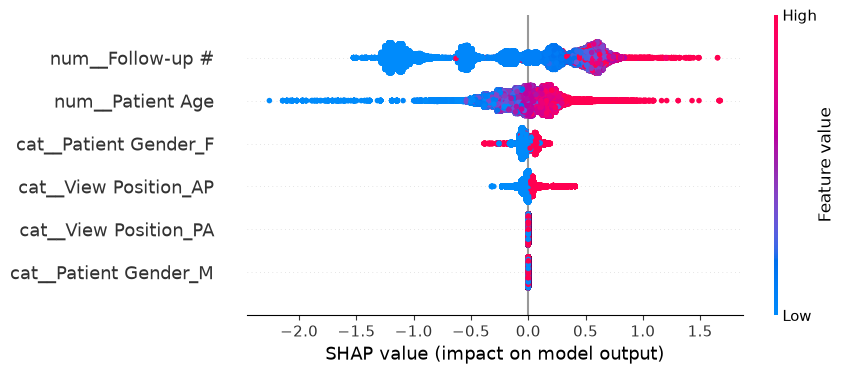

In [20]:
import shap
import matplotlib.pyplot as plt

# Fit XGB on full dataset
xgb_model.fit(X, y)

# Calculate SHAP values after transforming the features for SHAP
fitted_preprocessor = xgb_model.named_steps["preprocessor"]
fitted_classifier = xgb_model.named_steps["classifier"]
X_transformed = fitted_preprocessor.transform(X)
feature_names = fitted_preprocessor.get_feature_names_out()
X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X.index)
explainer = shap.TreeExplainer(fitted_classifier)
shap_values = explainer(X_transformed_df)

# Plot feature importance and direction
shap.plots.beeswarm(shap_values, max_display=10)

## 09. Clinical Interpretation and Rationale for metadata baseline

This project establishes a metadata-only baseline for predicting Effusion in the NIH ChestX-ray14 dataset, using patient age, gender, view position, and follow-up number. The XGBoost model achieved a mean ROC-AUC of 0.6750 and average precision of 0.1921 across 5 patient-level cross-validation folds. 

Among the metadata features, follow-up number was the strongest predictor of Effusion, followed by patient age. Higher follow-up numbers and older age generally pushed predictions towards the Effusion label. However, follow-up number may reflect imaging history or dataset-specific patterns rather than a direct clinical risk factor.

View position (AP vs PA) had a comparatively small influence on model predictions, as did gender. Although Effusion prevalence was higher among AP images in the initial dataset exploration, this association does not establish that view position causes Effusion or that AP imaging produces false-positive findings. Rather, patients who are non-ambulant or more acutely unwell are often the group that undergoes the AP images, and may therefore contribute to the higher Effusion prevalence.

These results suggest that metadata contains some predictive signal and associations with Effusion. This baseline provides a reference point for the next stage: training models on the actual chest X-ray images, where convolutional nerual networks (CNNs) can learn visual features associated with findings such as pleural fluid. 

Comparing the metadata-only baseline with a combined metadata-and-image model, will help assess the additional predictive value of image-derived features beyond patient context. All models will require careful validation, and the dataset's imperfect labels and potential biases should be considered.